In [1]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import numpy as np
from pathlib import Path

import sys
sys.path.insert(0, str(Path().resolve() / "helpers"))

import clean_human_survey as cs
import aggregation_analysis as aa
import plot_helper as ph

### Data Cleaning

In [ ]:
# ---- Scenario config: the only cell to change for a new scenario ----
root = Path().resolve().parent.parent
csv_path = Path.home() / "Downloads" / \
    "brother_1_choice_1_raw.csv"
output_path = root / "human_data" / "moral_comp_exp4" / "pilot" / "brother_1_choice_1_clean.csv"

# Correct answer for every attention check (ImportId -> option text, or a rule on the slider value).
# Run the next cell to list this survey's attention checks and their ImportIds.
ATTENTION_ANSWERS = {
    "QID92":    "Extremely worrying messages about harming himself and feeling hopeless",
    "QID150_1": lambda v: v != -100,   # bomb in community center: any value except -100
    "QID151_1": lambda v: v == -100,   # Sally crushed by trolley: exactly -100
    "QID99":    "My parents become aware that my brother is feeling hopeless and talking about harming himself",
    "QID152":   "knew/intend/cause",
    "QID154":   "-100 is equal to very painful death(s) for the character/group.",
    "QID122":   "My brother feels exposed and betrayed",
    "QID153":   "knew/intend/cause",
    "QID155":   "+100 is equal to perfect peace and happiness for the character/group.",
}

# Hard-coded exclusions, by Qualtrics response ID
EXCLUDED_IDS = [
    "R_11gEtdpv1iRjiCR",   # Subject 0
    "R_7ZQPyqBlZ7Vr0Ng",   # Subject 6 (off-topic sentience answer)
]

MIN_ATTENTION_CORRECT = 6

In [ ]:
# Check the detected survey layout (characters, outcomes, attention checks)
df, codebook = cs.load_qualtrics(csv_path)
structure = cs.detect_structure(codebook)
cs.describe_structure(structure, codebook)

In [ ]:
result = cs.clean_survey(csv_path, ATTENTION_ANSWERS,
                         excluded_ids=EXCLUDED_IDS,
                         min_attention_correct=MIN_ATTENTION_CORRECT)
clean = result.clean

print("Exclusions:")
print(result.exclusions["reason"].value_counts().to_string())

# Number and percentage of participants who missed each attention check
missed = ~result.attention_checks
missed_summary = pd.DataFrame({"missed": missed.sum(),
                               "missed_%": (100 * missed.mean()).round(1)})
print(f"\nAttention checks missed (before the cutoff, n={len(missed)}):")
print(missed_summary.to_string())

clean.shape

In [ ]:
clean.to_csv(output_path, index=False)

### Descriptive Statistics

In [2]:
# ---- Analysis data: read from the repo, independent of the cleaning section above ----
data_path = Path().resolve().parent.parent / "human_data" / "moral_comp_exp4" / "pilot" / "brother_1_choice_1_clean.csv"
clean = pd.read_csv(data_path)

# Copied from the "Characters:" and "Outcomes:" lines printed by the layout check above (same order)
char_labels = ["...", "..."]
outcome_labels = ["...", "...", "..."]

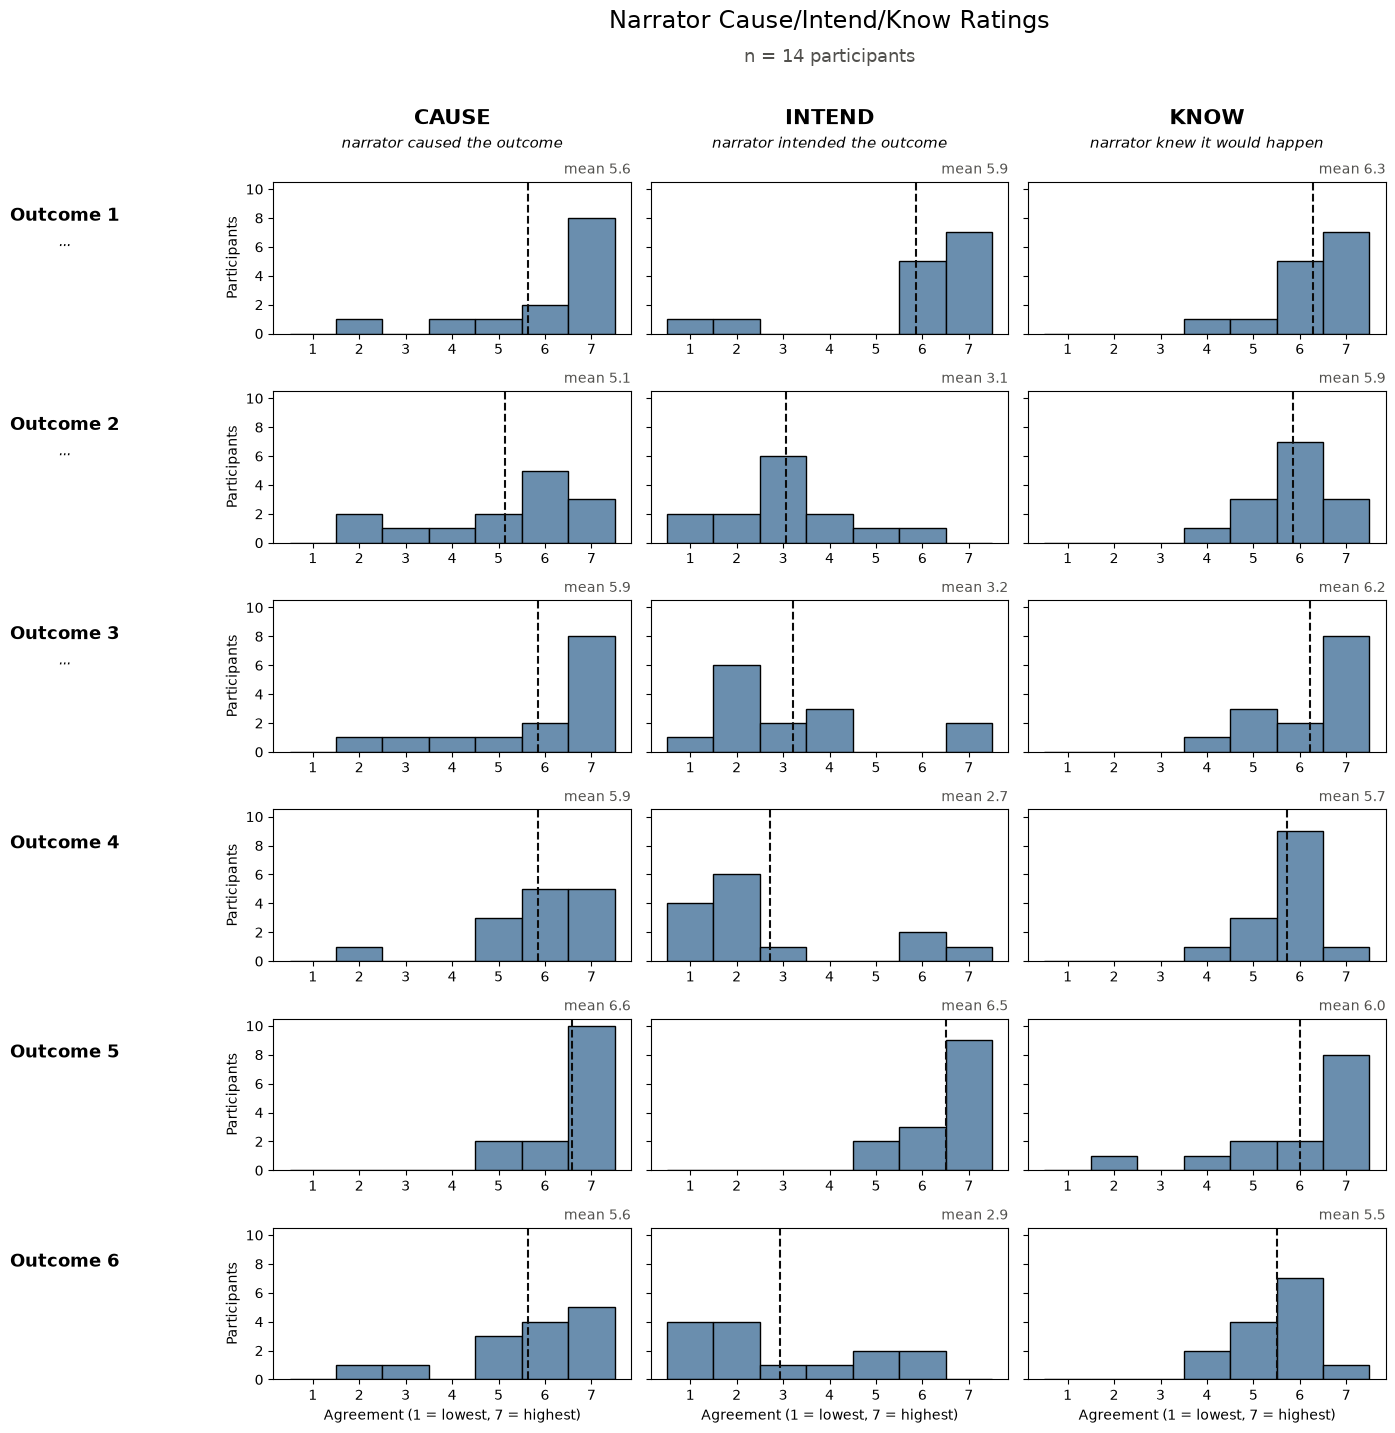

In [3]:
# CIK links: narrator Cause / Intend / Know ratings for each outcome
fig_cik = ph.plot_cik(clean, outcome_labels)

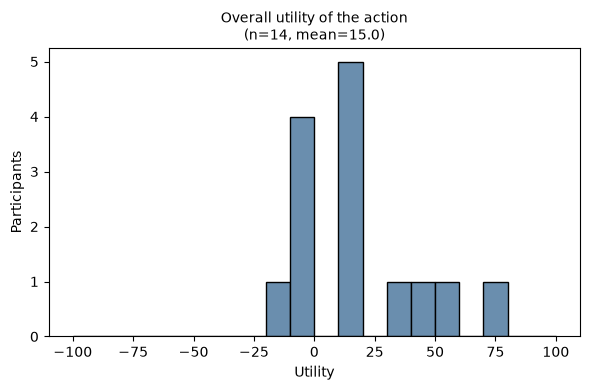

In [4]:
# Overall utility of the action
fig_overall = ph.plot_overall_utility(clean)

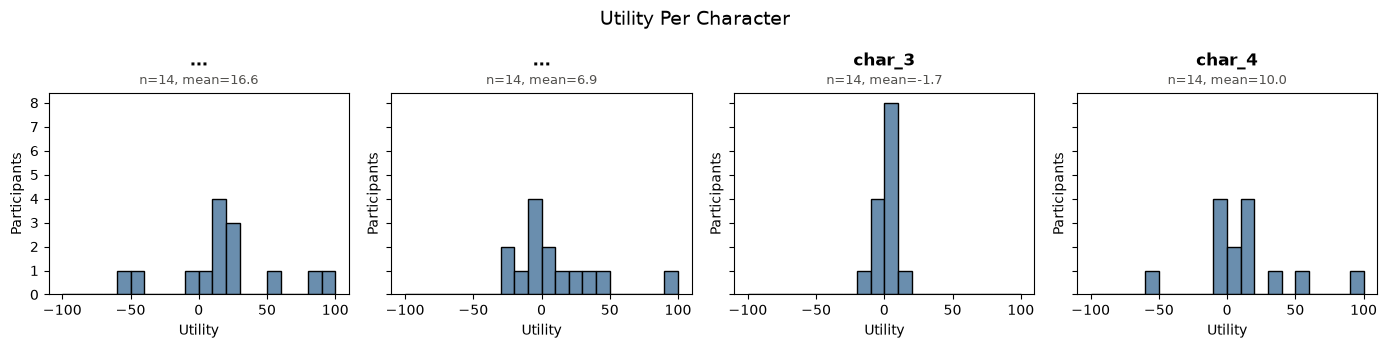

In [5]:
# Per-character utility of the action (not per outcome)
fig_char = ph.plot_char_utilities(clean, char_labels)

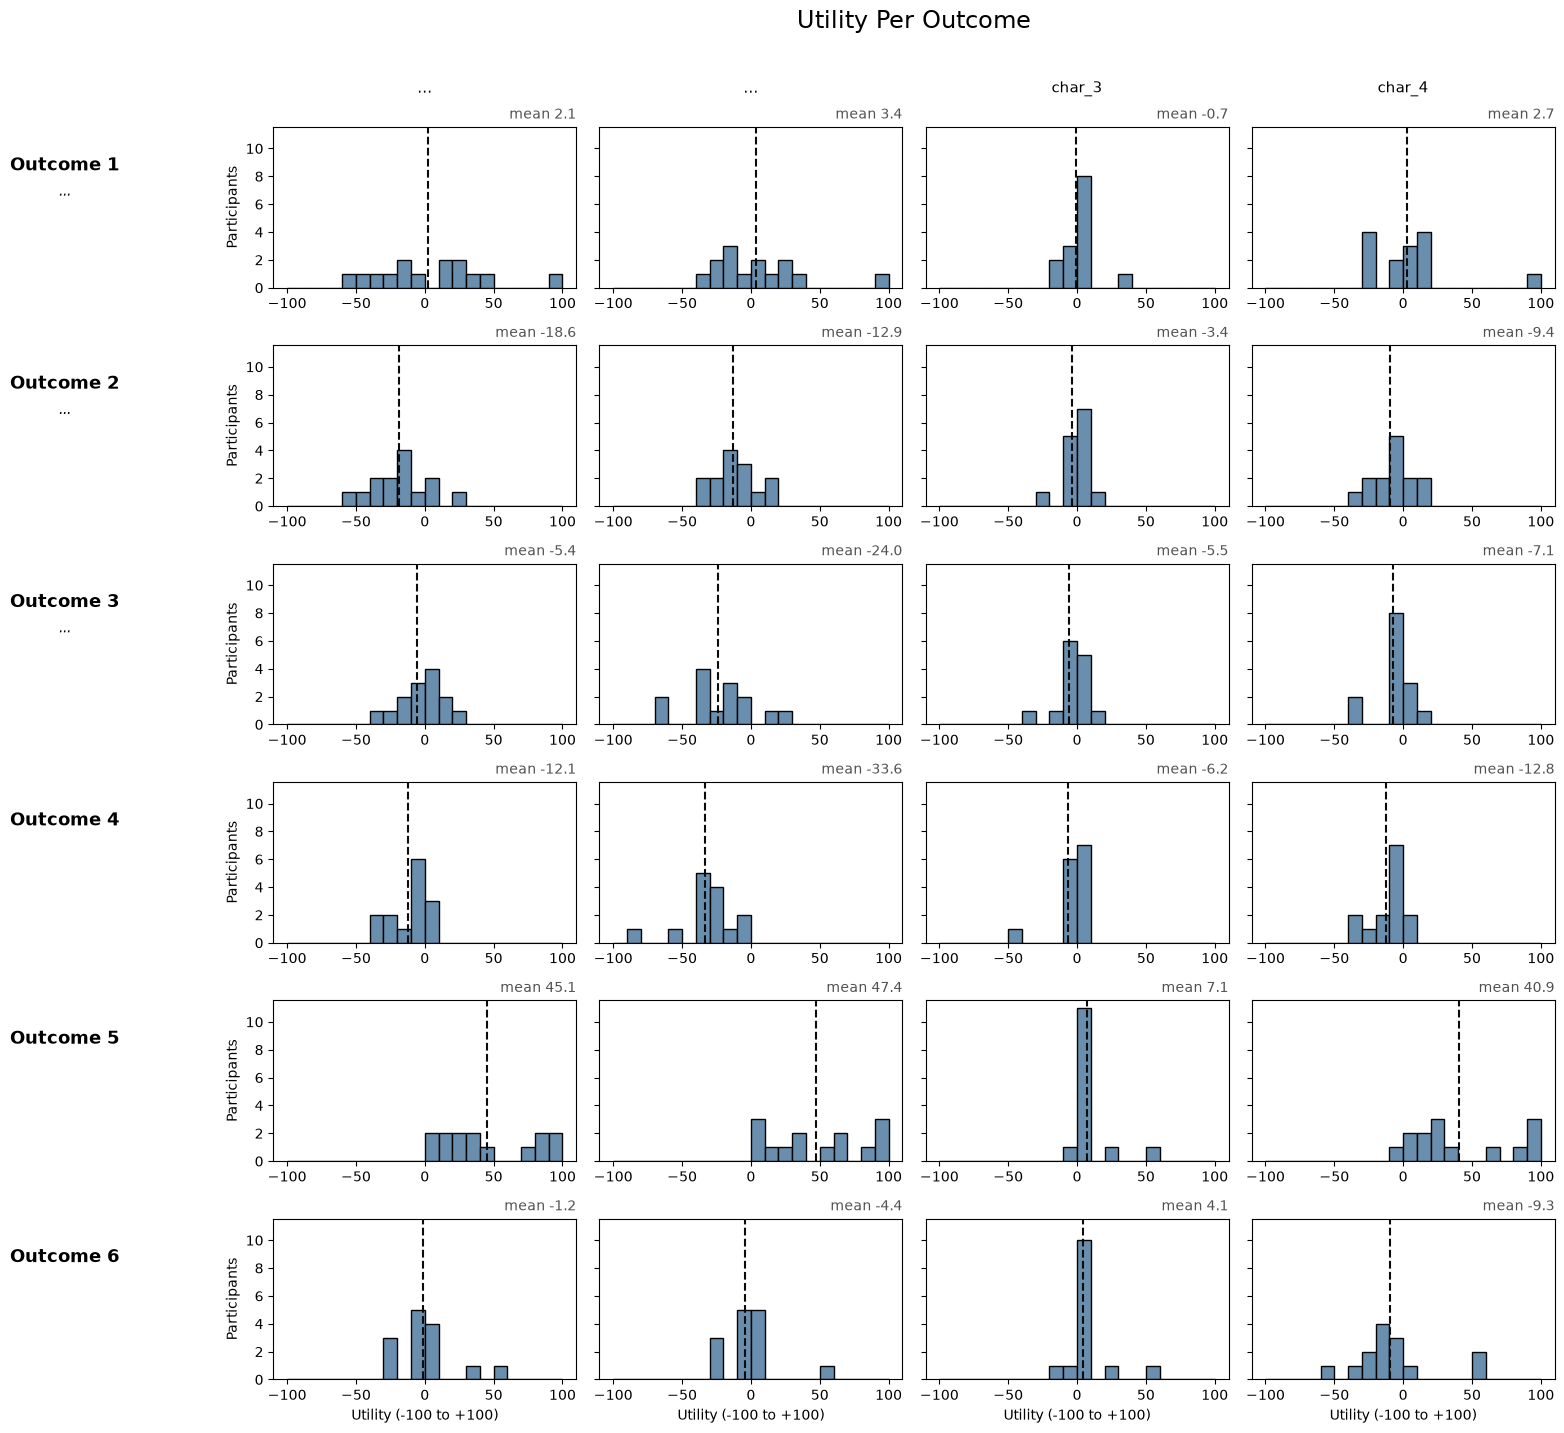

In [6]:
# For each outcome: per-character utility
fig_outcome_char = ph.plot_outcome_char_utilities(clean, char_labels, outcome_labels)

### Utility Aggregations

(a) Sum of a character's per-outcome utilities vs. that character's rated utility  
(b) Sum of all per-outcome, per-character utilities vs. the overall utility  
(c) Sum of the per-character utilities vs. the overall utility

In [7]:
# Per-participant sums
agg = aa.utility_aggregations(clean)
agg

,Subject,overall_utility,char_1_utility,char_1_outcome_sum,char_2_utility,char_2_outcome_sum,char_3_utility,char_3_outcome_sum,char_4_utility,char_4_outcome_sum,sum_outcome_utility,sum_char_utility
0,0,19.0,25.0,67.0,45.0,89.0,-10.0,12.0,15.0,28.0,196.0,75.0
1,1,10.0,17.0,57.0,-10.0,11.0,0.0,-10.0,13.0,11.0,69.0,20.0
2,2,35.0,20.0,-35.0,30.0,0.0,-5.0,-20.0,10.0,-20.0,-75.0,55.0
3,3,-14.0,3.0,-60.0,-30.0,-130.0,0.0,0.0,-10.0,-89.0,-279.0,-37.0
4,4,-10.0,-10.0,-124.0,-10.0,-128.0,0.0,0.0,0.0,-8.0,-260.0,-20.0
5,5,40.0,54.0,-4.0,-20.0,-166.0,0.0,0.0,35.0,-83.0,-253.0,69.0
6,6,-5.0,-60.0,-110.0,0.0,-70.0,-10.0,-40.0,-60.0,-115.0,-335.0,-130.0
7,7,70.0,80.0,18.0,-5.0,-7.0,5.0,18.0,50.0,11.0,40.0,130.0
8,8,50.0,-47.0,11.0,2.0,-84.0,-12.0,-87.0,0.0,131.0,-29.0,-57.0
9,9,10.0,10.0,25.0,10.0,23.0,3.0,8.0,10.0,21.0,77.0,33.0


In [8]:
# How well each summed utility recovers the rated one
pairs = aa.comparison_pairs(clean, char_labels)
aa.aggregation_summary(agg, pairs)

,comparison,rated_mean,summed_mean,mean_diff (summed - rated),pearson_r
0,(a) ...: sum over outcomes vs. rated character...,16.57,9.79,-6.79,0.69
1,(a) ...: sum over outcomes vs. rated character...,6.93,-24.21,-31.14,0.85
2,(a) char_3: sum over outcomes vs. rated charac...,-1.71,-4.64,-2.93,0.75
3,(a) char_4: sum over outcomes vs. rated charac...,10.00,5.00,-5.00,0.71
4,(b) sum over outcomes and characters vs. overa...,15.00,-14.07,-29.07,-0.04
5,(c) sum of character utilities vs. overall uti...,15.00,31.79,16.79,0.14


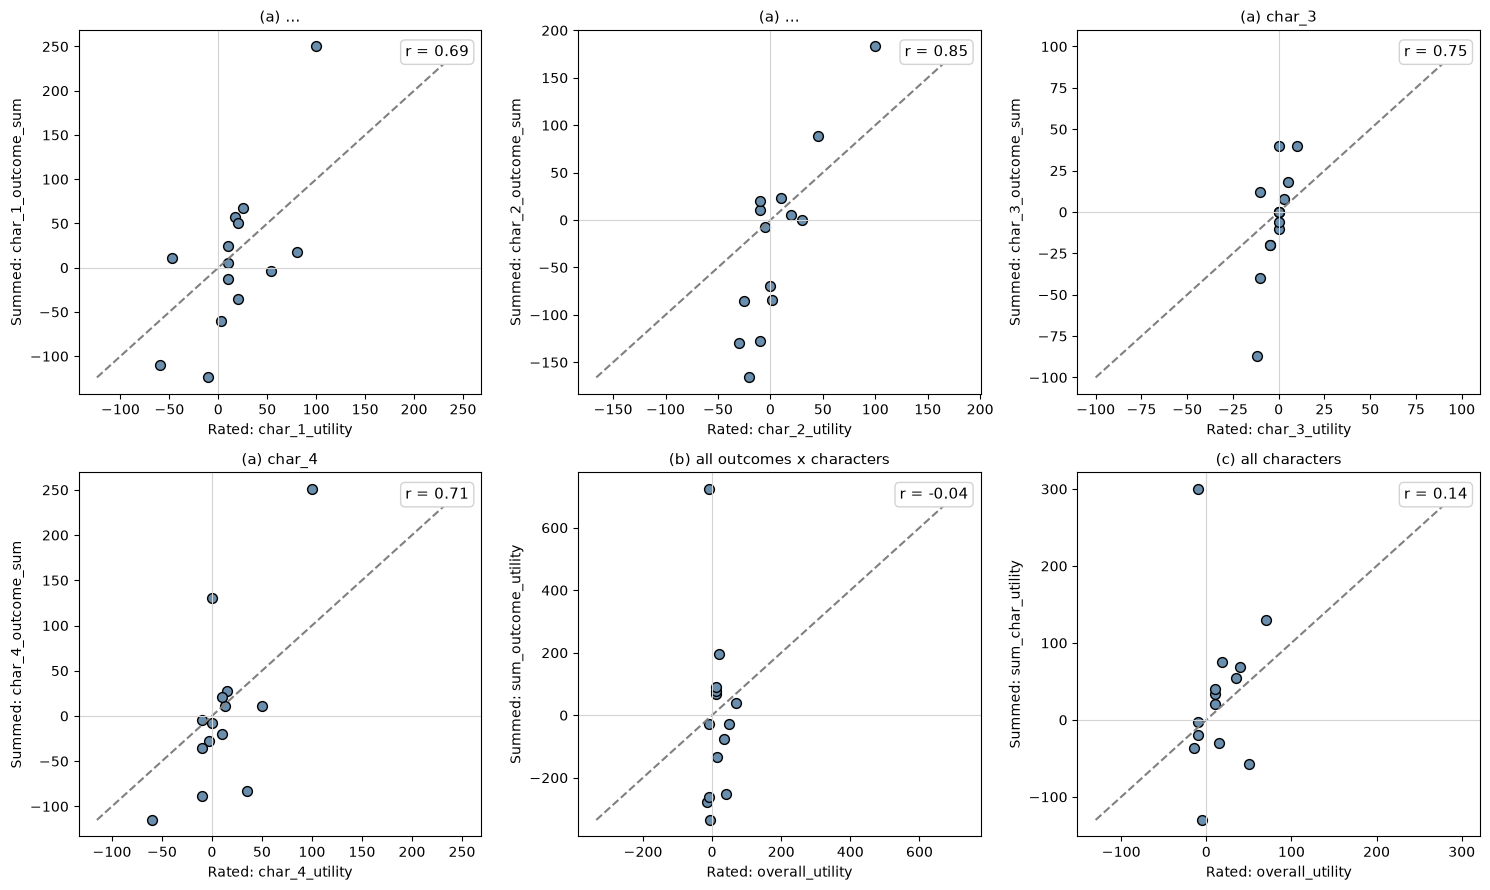

In [9]:
# Summed vs. rated utility per participant (dashed line = perfect recovery)
fig_agg = ph.plot_aggregations(agg, pairs)